In [668]:
# Built in packages
import math
import sys
from pathlib import Path

# Matplotlib will need to be installed if it isn't already. This is the only package allowed for this base part of the 
# assignment.
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle, Polygon

import numpy as np

import importlib

from reader import ImageReader 
import denoise
import thresholder
import decomposer

In [669]:
img = ImageReader("images/Barcode7.png")

img_rgb = np.dstack((img.r, img.g, img.b))

read image width=992, height=875


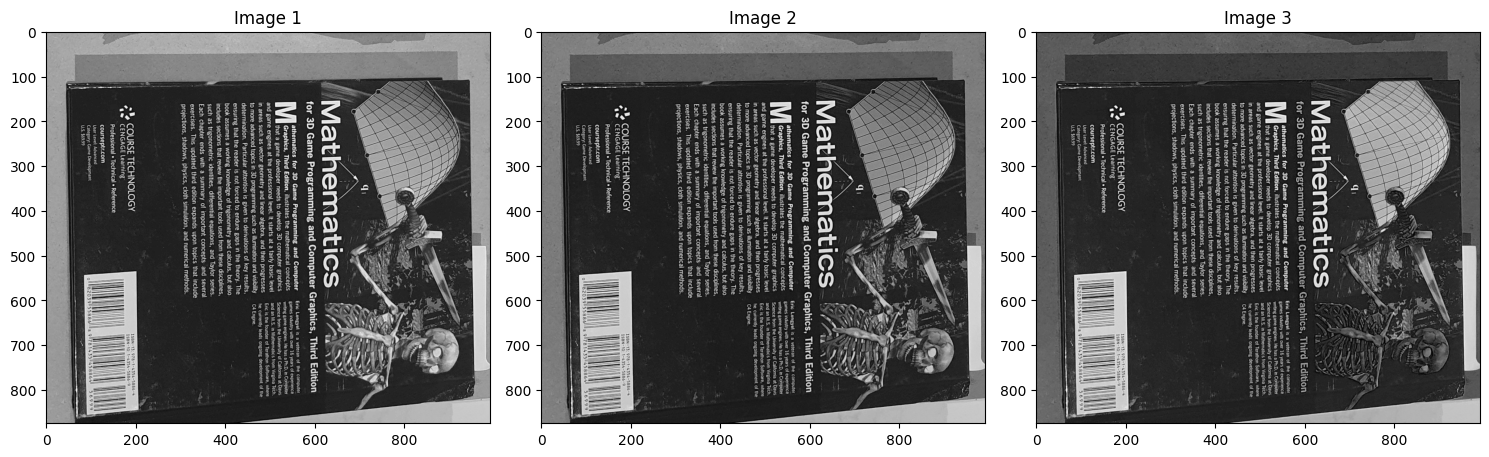

In [670]:
def show_all_pipes(imgs, titles=[], real_scale=False):
    n = len(imgs)
    plt.figure(figsize=(5 * n, 5))

    if not len(titles):
        titles = [f'Image {i + 1}' for i in range(n)]

    for i, img in enumerate(imgs):
        plt.subplot(1, n, i + 1)
        if real_scale:
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(img, cmap='gray')
        plt.title(titles[i])

    plt.tight_layout()
    plt.show()

show_all_pipes([img.r, img.g, img.b], real_scale=True)

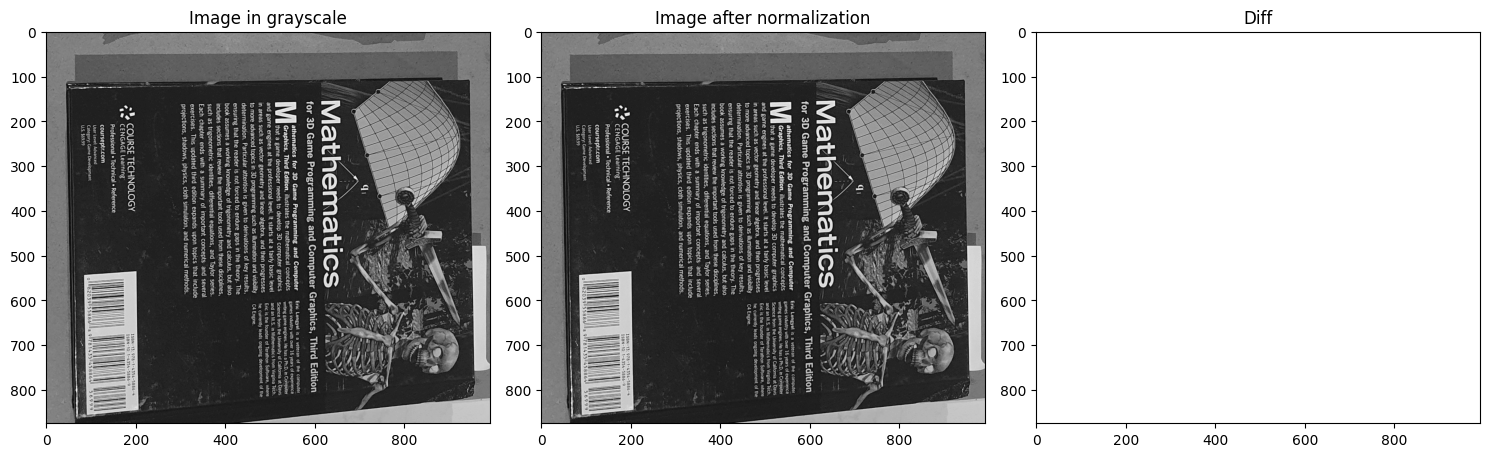

In [671]:
def grayout(r, g, b):
    return (r + g + b) / 3

def normalize(arr):
    mi, mx = np.min(arr), np.max(arr)
    normalizer = lambda x: round((x - mi) / (mx - mi) * 255) if mi != mx else 128
    return np.vectorize(normalizer)(arr)

im = grayout(img.r, img.g, img.b)
im_norm = normalize(im)
show_all_pipes([im, im_norm, 255 - np.abs(im - im_norm)], ["Image in grayscale", "Image after normalization", "Diff"], real_scale=True)

In [672]:
def apply_standard_deviation_filter(arr, size: int = 5):
    filtered_image = np.zeros_like(arr, dtype=np.float64)
    padded_image = np.pad(arr, ((size // 2, size // 2), (2, 2)), mode='edge')

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            region = padded_image[i:i + size, j:j + size]
            filtered_image[i, j] = np.std(region)

    return filtered_image

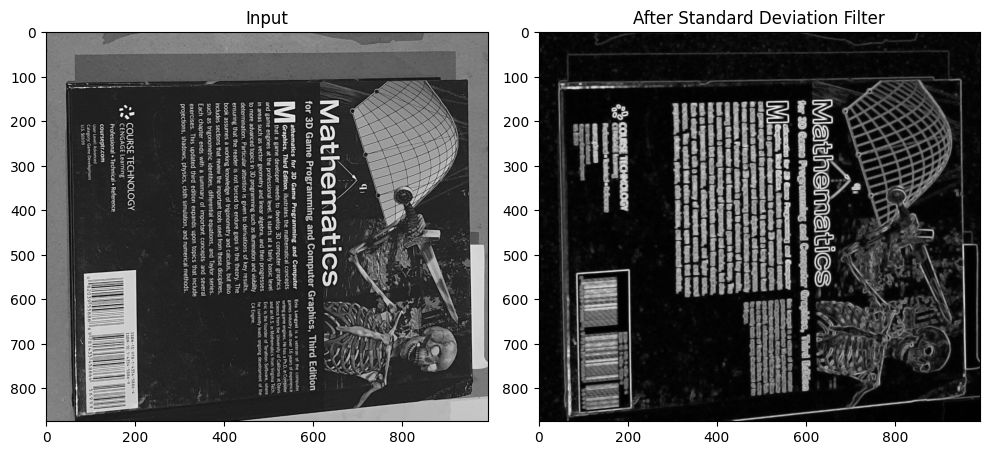

In [673]:
sd = apply_standard_deviation_filter(im_norm)
show_all_pipes([im_norm, sd], ["Input", "After Standard Deviation Filter"])

In [674]:
def apply_gaussian_filter(image, size: int = 3, sigma: float = 1.5, print_kernel: bool = False):
    kernel = np.fromfunction(lambda x, y: (1 / (2 * np.pi * sigma**2)) * np.exp(-((x - size // 2)**2 + (y - size // 2)**2) / (2 * sigma**2)), (size, size))
    kernel = kernel / np.sum(kernel)

    if print_kernel:
        print("Kernel:\n", kernel)

    pad_width = size // 2
    padded_image = np.pad(image, pad_width, mode='edge')

    filtered_image = np.zeros_like(image, dtype=np.float64)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded_image[i:i+size, j:j+size]
            filtered_image[i, j] = np.sum(region * kernel)

    return filtered_image

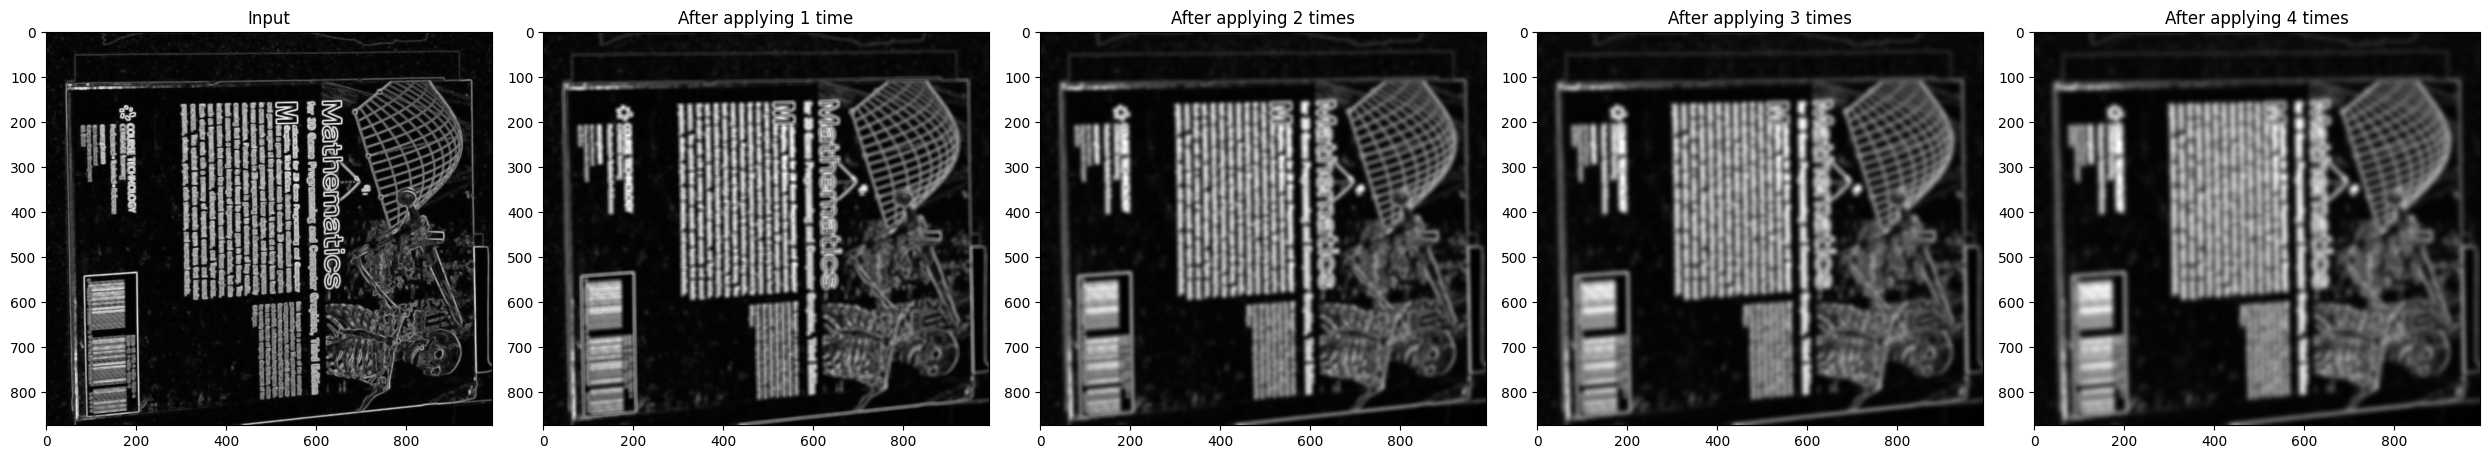

In [675]:
n = 4
sigma = 14
size = 9

gausses = [sd.copy()] + [None] * n
titles = ["Input"] + [f"After applying {i + 1} time{'s' if i else ''}" for i in range(n)]
for i in range(n):
    gausses[i+1] = apply_gaussian_filter(gausses[i], sigma=sigma, size=size)

show_all_pipes(gausses, titles)
gauss: np.ndarray = gausses[-1] # type: ignore

[0.09217422 0.09593593 0.09896751 0.10119141 0.10254966 0.10300645
 0.10254966 0.10119141 0.09896751 0.09593593 0.09217422]


C:\Users\taken\AppData\Local\Temp\ipykernel_44428\467088338.py:1: RuntimeWarning: divide by zero encountered in log
  hist = np.log(np.histogram(gauss, bins=256, range=(0, 256))[0])


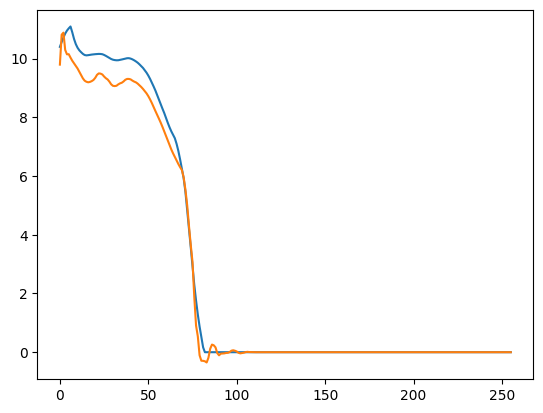

In [676]:
hist = np.log(np.histogram(gauss, bins=256, range=(0, 256))[0])
hist[np.isinf(hist)] = 0
hist_smoothed_gauss = denoise.kernal_denoise_1d(hist, 'gauss', size=11, sigma=15)
hist_smoothed_wavelet = denoise.wavelet_denoise_1d(hist, level=3)

plt.figure()
plt.plot(hist_smoothed_gauss)
plt.plot(hist_smoothed_wavelet)
plt.show()


In [677]:
try:
    print("Mean Threshold: ", thresholder.eval_hist_threshold(hist_smoothed_gauss))
    print("Otsu Threshold: ", thresholder.eval_hist_threshold(hist_smoothed_gauss, 'otsu'))
    print("double_peaks_max Threshold: ", thresholder.eval_hist_threshold(hist_smoothed_gauss, 'double_peaks_max'))
    print("double_peaks_min Threshold: ", thresholder.eval_hist_threshold(hist_smoothed_gauss, 'double_peaks_min'))
except Exception as e:
    pass

Mean Threshold:  34.37960853898741
Otsu Threshold:  36
double_peaks_max Threshold:  32
double_peaks_min Threshold:  15


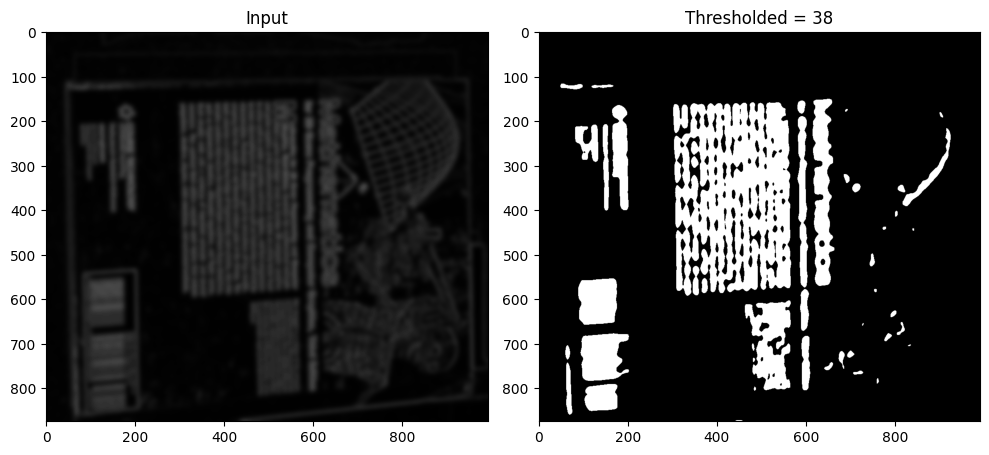

In [678]:
def binarize(img, threahold: int = 25):
    thresholded = np.where(img < threahold, 0, img)
    thresholded = np.where(img >= threahold, 1, thresholded)
    return thresholded

threshold = thresholder.eval_hist_threshold(hist_smoothed_gauss, 'otsu') + 2
thresholded = binarize(gauss, threshold) * 255

show_all_pipes([gauss, thresholded], ["Input", f"Thresholded = {threshold}"], real_scale=True)

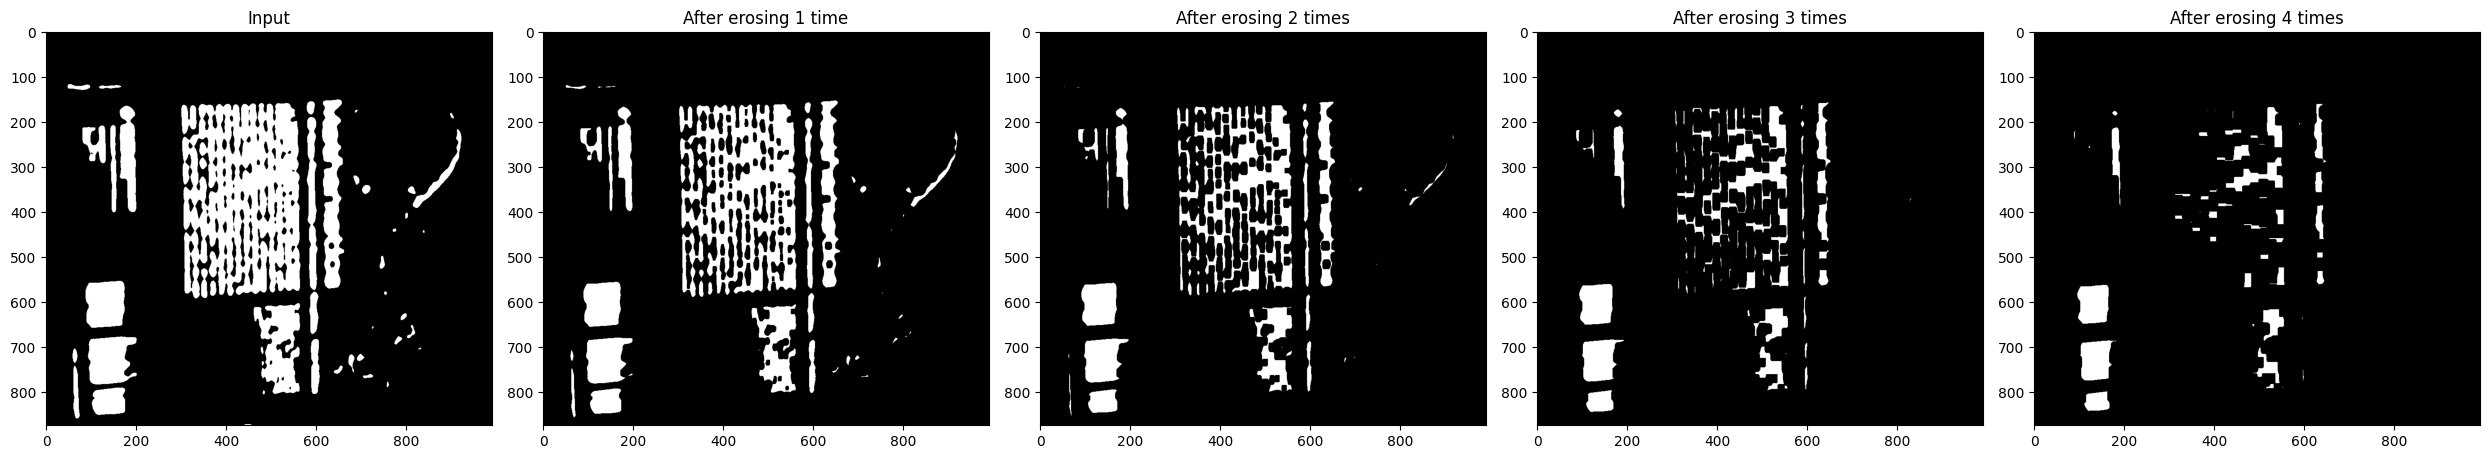

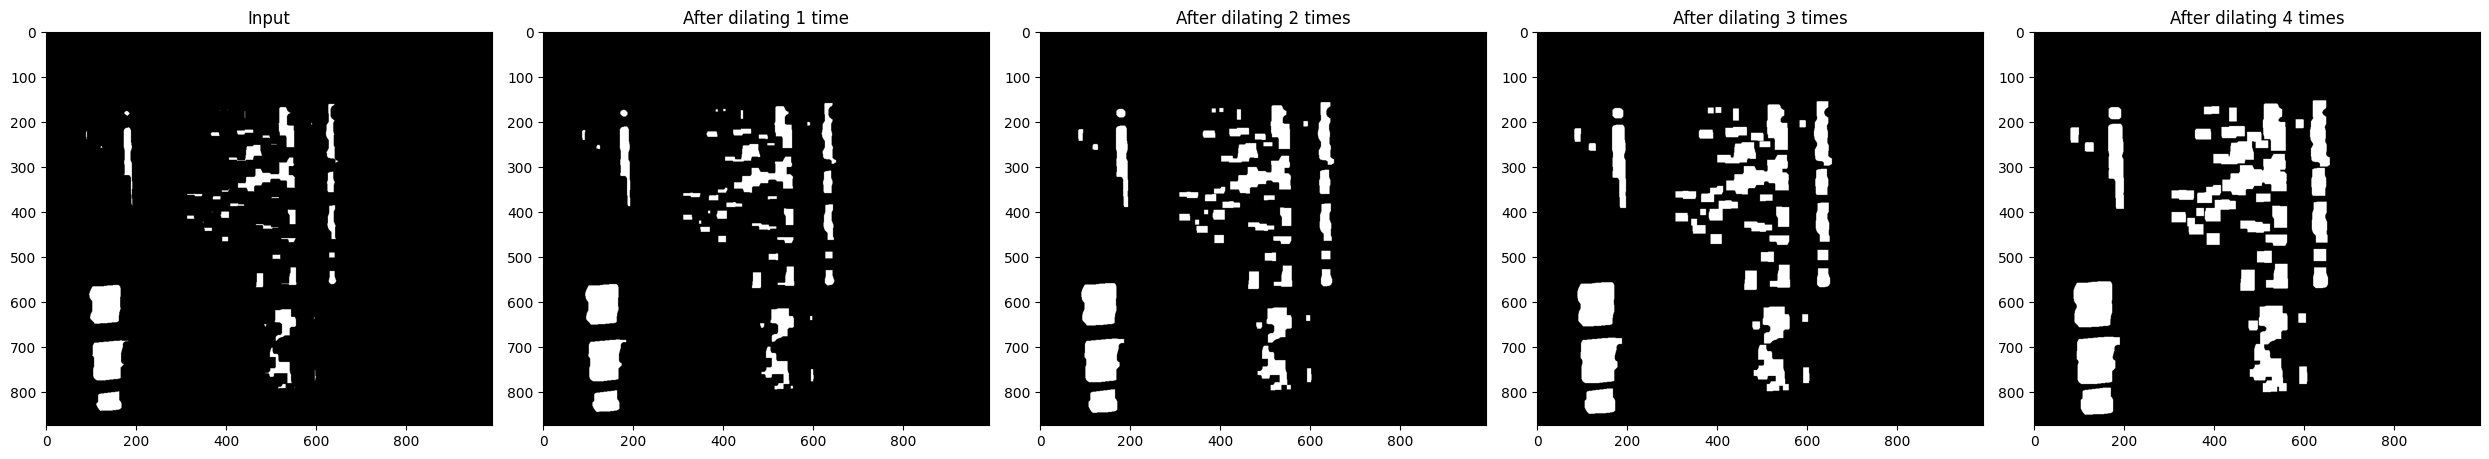

In [694]:
def erosion_or_dilation(image, size, erosion=True):
    height, width = image.shape

    result = np.zeros_like(image)

    for y in range(size, height - size):
        for x in range(size, width - size):
            region = image[y - size:y + size + 1, x - size: x + size + 1]
            new_value = np.min(region) if erosion else np.max(region)
            result[y, x] = new_value

    return result

n = 4
eroses = [thresholded.copy()] + [None] * n
titles = ["Input"] + [f"After erosing {i + 1} time{'s' if i else ''}" for i in range(n)]
for i in range(n):
    eroses[i+1] = erosion_or_dilation(eroses[i], 2)
show_all_pipes(eroses, titles)
eros: np.ndarray = eroses[-1] # type: ignore

dilateds = [eros.copy()] + [None] * n
titles = ["Input"] + [f"After dilating {i + 1} time{'s' if i else ''}" for i in range(n)]
for i in range(n):
    dilateds[i+1] = erosion_or_dilation(dilateds[i], 2, False)

show_all_pipes(dilateds, titles)
dilated: np.ndarray = dilateds[-1] # type: ignore


In [701]:
importlib.reload(decomposer)

<module 'decomposer' from 'd:\\projects\\CS373_2023_Assignment_Barcode_Detection\\decomposer.py'>

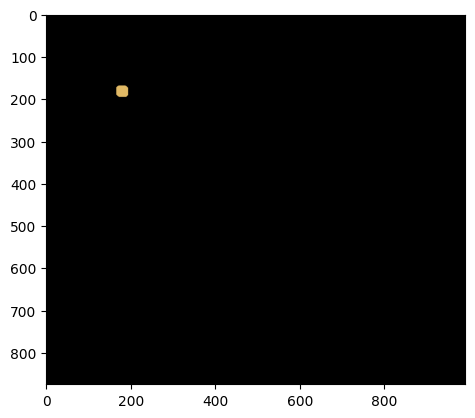

In [704]:
labels, label_num = decomposer.get_connected_components(dilated)

decomposer.plot_components(labels, [4])

In [710]:
def is_barcode(labels, label, original):
    info = decomposer.get_components_info(labels, label, original)
    if abs(info.cover - 1) > 0.3 or info.size < 400 or info.minor_radius < 30 or info.major_radius < 30:
        return False, info
    return True, info

32 corners:  [[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]
major_axis:  [53.62758506 -6.32152974]
major_radius:  53
minor_axis:  [ 5.15087544 43.69721092]
minor_radius:  43
center:  [605.8842  131.49223]
size:  9116
cover:  0.8896445809565598

36 corners:  [[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]
major_axis:  [ 55.61398841 -16.46932066]
major_radius:  58
minor_axis:  [13.0610565  44.10626747]
minor_radius:  45
center:  [729.61914 138.05058]
size:  10440
cover:  0.8047892720306513



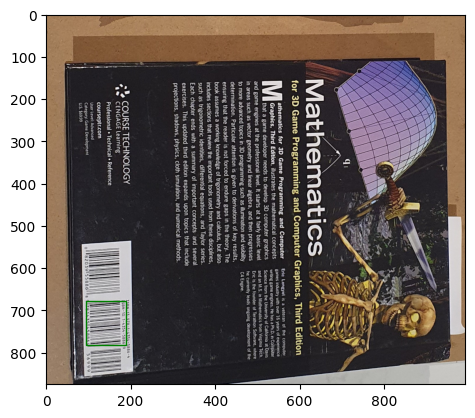

In [712]:
fig, ax = plt.subplots()

mx_size = 0
mx_rect = decomposer.Rect(0, 0, 0, 0)
for i in range(1, label_num + 1):
    rect = decomposer.get_outer_box(labels, i)

    isbarcode, info = is_barcode(labels, i, None)
    if info.size > mx_size and isbarcode:
        mx_size = info.size
        mx_rect = rect
        #print(i, info)

rectangle = Rectangle((mx_rect.top, mx_rect.left),
                          mx_rect.height, mx_rect.width, edgecolor='g', facecolor='none')

ax.add_patch(rectangle)

ax.set_xlim(0, img.width)
ax.set_ylim(img.height, 0)
#decomposer.plot_components(labels)
plt.imshow(img_rgb.astype(np.uint8))
plt.savefig("asdf")


In [ ]:
corners.T

array([[604, 604, 599, 599],
       [272, 261, 261, 272]])